# Compare the rebuilt SFINCS runs: maximum water depth and maximum water level

Compares `subgrid_200m` and `subgrid_400m` against the regular 100 m reference (`regular_100m`).

- **Maximum depth (hmax):** for every run, `zsmax` (maximum over the whole simulation) is downscaled onto the
  100 m DEM: `hmax = max(zsmax - dem_100m, 0)`. Each 200 m / 400 m cell covers an exact 2x2 / 4x4 block of DEM cells.
- **Maximum water level (zsmax):** compared on the same 100 m grid, only in cells flooded in the reference
  (hmax > 5 cm); elsewhere the regular zsmax is undefined (never wet).

Run the models first (`models/rebuild/run_sfincs_all.bat`, see `scripts/sfincs_rebuild/write_batch.py`).


### Imports and paths

In [1]:
from pathlib import Path
import sys

import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parents[1]  # notebooks/sfincs_rebuild -> repository root
sys.path.insert(0, str(PROJECT_ROOT))

from scripts.sfincs_rebuild.compare import compare_all, plot_case, plot_summary, summarize

MODEL_ROOT = PROJECT_ROOT / "models" / "rebuild"
OUTPUT_FOLDER = PROJECT_ROOT / "outputs" / "rebuild"
case_table = pd.read_csv(OUTPUT_FOLDER / "case_table.csv")

## Metrics per case

In [2]:
comparison = compare_all(case_table, PROJECT_ROOT, MODEL_ROOT, out_csv=OUTPUT_FOLDER / "comparison.csv")
print(comparison["status"].value_counts())
comparison.head()

status
ok    378
Name: count, dtype: int64


,case_name,split,topography,rainfall,grid,variant,rmse_hmax_m,mae_hmax_m,bias_hmax_m,max_hmax_ref_m,...,rmse_zsmax_m,mae_zsmax_m,bias_zsmax_m,p95_abs_zsmax_m,max_abs_zsmax_m,n_cells_zsmax,rain_volume_m3,runtime_s,runtime_ref_s,status
0,DEM_41_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,flat,L3_RP100_temporal_uniform.prcp,64x64,regular_100m,0.000000,0.000000,0.000000,1.206178,...,0.000000,0.000000,0.000000,0.000000,0.000000,2074,7.579443e+06,2.809,2.809,ok
1,DEM_41_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,flat,L3_RP100_temporal_uniform.prcp,64x64,subgrid_200m,0.017232,0.015446,-0.002160,1.206178,...,0.015561,0.013586,0.010607,0.028454,0.084716,2074,7.580094e+06,1.449,2.809,ok
2,DEM_41_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,flat,L3_RP100_temporal_uniform.prcp,64x64,subgrid_400m,0.029524,0.023796,-0.003675,1.206178,...,0.036643,0.028664,0.006843,0.067383,0.195226,2074,7.579280e+06,1.188,2.809,ok
3,DEM_37_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,flat,L3_RP100_temporal_uniform.prcp,64x64,regular_100m,0.000000,0.000000,0.000000,0.983526,...,0.000000,0.000000,0.000000,0.000000,0.000000,2521,7.579833e+06,2.406,2.406,ok
4,DEM_37_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,flat,L3_RP100_temporal_uniform.prcp,64x64,subgrid_200m,0.014648,0.011850,-0.000694,0.983526,...,0.012989,0.009523,0.007440,0.024238,0.127700,2521,7.579280e+06,1.799,2.406,ok


## Summary per split and variant

In [3]:
summarize(comparison).round(4)

rmse_hmax_m  mae_hmax_m  \
split                           variant                                 
test_unseen_domain              regular_100m       0.0000      0.0000   
                                subgrid_200m       0.0263      0.0201   
                                subgrid_400m       0.0361      0.0248   
test_unseen_domain_and_rainfall regular_100m       0.0000      0.0000   
                                subgrid_200m       0.0264      0.0209   
                                subgrid_400m       0.0393      0.0283   
test_unseen_rainfall            regular_100m       0.0000      0.0000   
                                subgrid_200m       0.0319      0.0244   
                                subgrid_400m       0.0519      0.0351   

                                              bias_hmax_m  max_hmax_error_m  \
split                           variant                                       
test_unseen_domain              regular_100m       0.0000            0.0000   
                                subgrid_200m      -0.0005            0.0604   
                                subgrid_400m      -0.0039            0.0934   
test_unseen_domain_and_rainfall regular_100m       0.0000            0.0000   
                                subgrid_200m      -0.0015            0.0301   
                                subgrid_400m      -0.0041            0.0570   
test_unseen_rainfall            regular_100m       0.0000            0.0000   
                                subgrid_200m       0.0004            0.0589   
                                subgrid_400m      -0.0046            0.0865   

                                                 csi  hit_rate  \
split                           variant                          
test_unseen_domain              regular_100m  1.0000    1.0000   
                                subgrid_200m  0.9200    0.9673   
                                subgrid_400m  0.8738    0.9253   
test_unseen_domain_and_rainfall regular_100m  1.0000    1.0000   
                                subgrid_200m  0.9383    0.9682   
                                subgrid_400m  0.8961    0.9346   
test_unseen_rainfall            regular_100m  1.0000    1.0000   
                                subgrid_200m  0.9154    0.9476   
                                subgrid_400m  0.8516    0.8922   

                                              false_alarm_ratio  rmse_zsmax_m  \
split                           variant                                         
test_unseen_domain              regular_100m             0.0000        0.0000   
                                subgrid_200m             0.0508        0.0405   
                                subgrid_400m             0.0611        0.0659   
test_unseen_domain_and_rainfall regular_100m             0.0000        0.0000   
                                subgrid_200m             0.0324        0.0350   
                                subgrid_400m             0.0455        0.0645   
test_unseen_rainfall            regular_100m             0.0000        0.0000   
                                subgrid_200m             0.0362        0.0501   
                                subgrid_400m             0.0527        0.1032   

                                              mae_zsmax_m  bias_zsmax_m  \
split                           variant                                   
test_unseen_domain              regular_100m       0.0000        0.0000   
                                subgrid_200m       0.0323        0.0239   
                                subgrid_400m       0.0466        0.0075   
test_unseen_domain_and_rainfall regular_100m       0.0000        0.0000   
                                subgrid_200m       0.0269        0.0162   
                                subgrid_400m       0.0459        0.0045   
test_unseen_rainfall            regular_100m       0.0000        0.0000   
                                subgrid_200m       0.0389        0.0200   
   

## Summary per topography (flat / sloped) and variant

In [4]:
summarize(comparison, by=("topography", "variant")).round(4)

rmse_hmax_m  mae_hmax_m  bias_hmax_m  \
topography variant                                              
flat       regular_100m       0.0000      0.0000       0.0000   
           subgrid_200m       0.0233      0.0184      -0.0010   
           subgrid_400m       0.0332      0.0229      -0.0047   
sloped     regular_100m       0.0000      0.0000       0.0000   
           subgrid_200m       0.0351      0.0262       0.0005   
           subgrid_400m       0.0526      0.0361      -0.0030   

                         max_hmax_error_m     csi  hit_rate  \
topography variant                                            
flat       regular_100m            0.0000  1.0000    1.0000   
           subgrid_200m            0.0483  0.9460    0.9860   
           subgrid_400m            0.0627  0.9096    0.9537   
sloped     regular_100m            0.0000  1.0000    1.0000   
           subgrid_200m            0.0699  0.8783    0.9222   
           subgrid_400m            0.1297  0.8048    0.8575   

                         false_alarm_ratio  rmse_zsmax_m  mae_zsmax_m  \
topography variant                                                      
flat       regular_100m             0.0000        0.0000       0.0000   
           subgrid_200m             0.0413        0.0332       0.0273   
           subgrid_400m             0.0487        0.0564       0.0404   
sloped     regular_100m             0.0000        0.0000       0.0000   
           subgrid_200m             0.0514        0.0576       0.0434   
           subgrid_400m             0.0718        0.1063       0.0745   

                         bias_zsmax_m  p95_abs_zsmax_m  runtime_s  n_cases  
topography variant                                                          
flat       regular_100m        0.0000           0.0000     4.2813       80  
           subgrid_200m        0.0222           0.0613     1.9253       80  
           subgrid_400m        0.0074           0.1076     1.3360       80  
sloped     regular_100m        0.0000           0.0000     5.7446       46  
           subgrid_200m        0.0217           0.1056     1.8667       46  
           subgrid_400m       -0.0006           0.2017     1.3133       46

## Largest errors

In [5]:
subgrid = comparison[comparison["variant"] != "regular_100m"]
subgrid.nlargest(10, "rmse_hmax_m")[["case_name", "split", "variant", "rmse_hmax_m", "csi", "max_hmax_error_m"]]

,case_name,split,variant,rmse_hmax_m,csi,max_hmax_error_m
47,DEM_500_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,subgrid_400m,0.101840,0.796047,0.177011
41,DEM_56_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,subgrid_400m,0.092518,0.832905,0.245468
53,DEM_23_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,subgrid_400m,0.091399,0.833211,0.023064
32,DEM_20_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,subgrid_400m,0.083376,0.855319,0.155287
263,DEM_3_sloped_10m_31deg_L3_RP100_temporal_unifo...,test_unseen_rainfall,subgrid_400m,0.080699,0.747973,0.179774
257,DEM_38_sloped_10m_243deg_L3_RP100_temporal_uni...,test_unseen_rainfall,subgrid_400m,0.077580,0.730112,0.178423
284,DEM_15001_sloped_5m_78deg_L3_RP050_temporal_un...,test_unseen_domain,subgrid_400m,0.068460,0.850544,0.088041
59,DEM_5_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,subgrid_400m,0.067823,0.875953,0.274466
287,DEM_15001_sloped_5m_78deg_L3_RP100_temporal_un...,test_unseen_domain_and_rainfall,subgrid_400m,0.063499,0.864170,0.119772
248,DEM_62_sloped_5m_99deg_L3_RP100_temporal_unifo...,test_unseen_rainfall,subgrid_400m,0.063179,0.794779,0.097300


## Maps: one case per split, plus the worst case

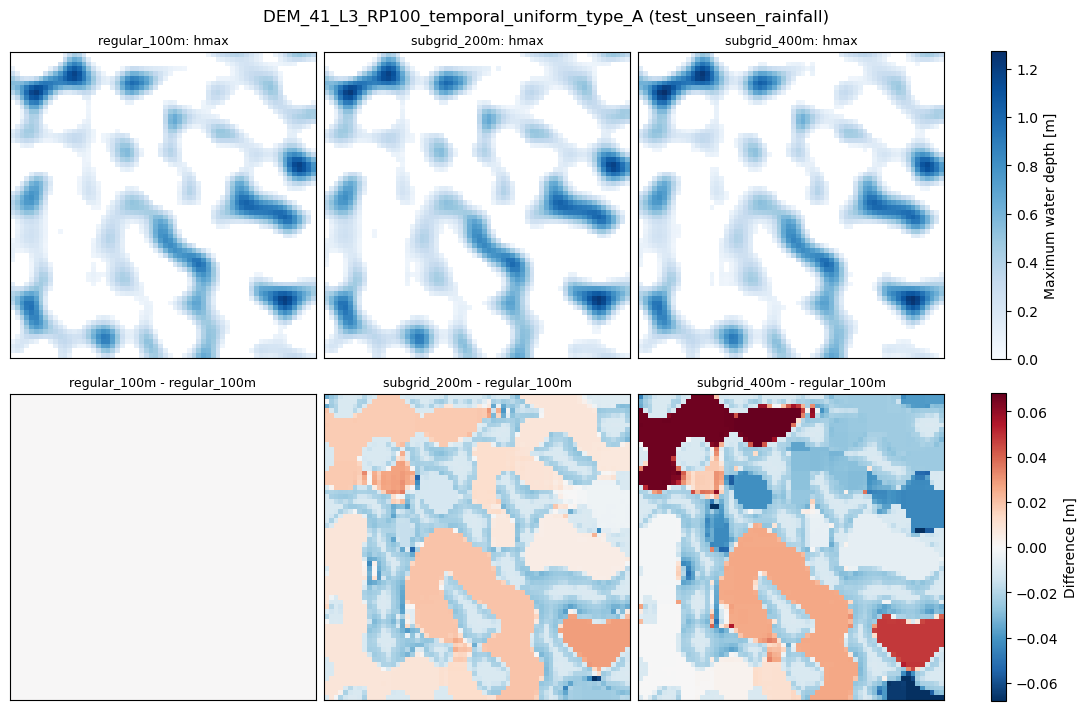

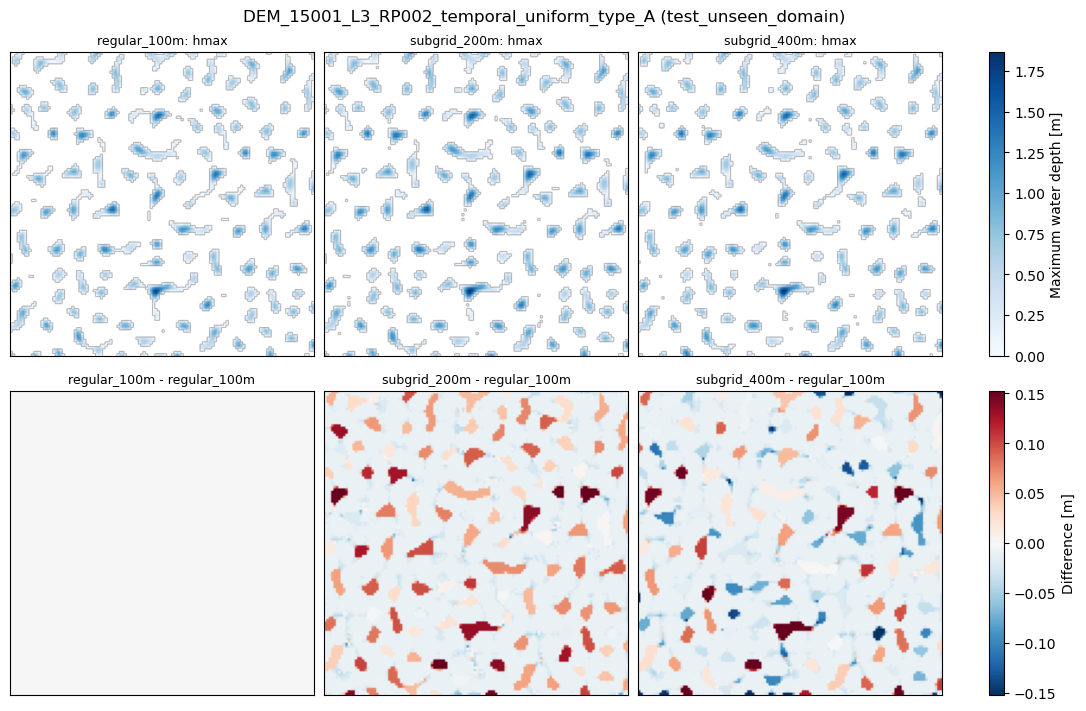

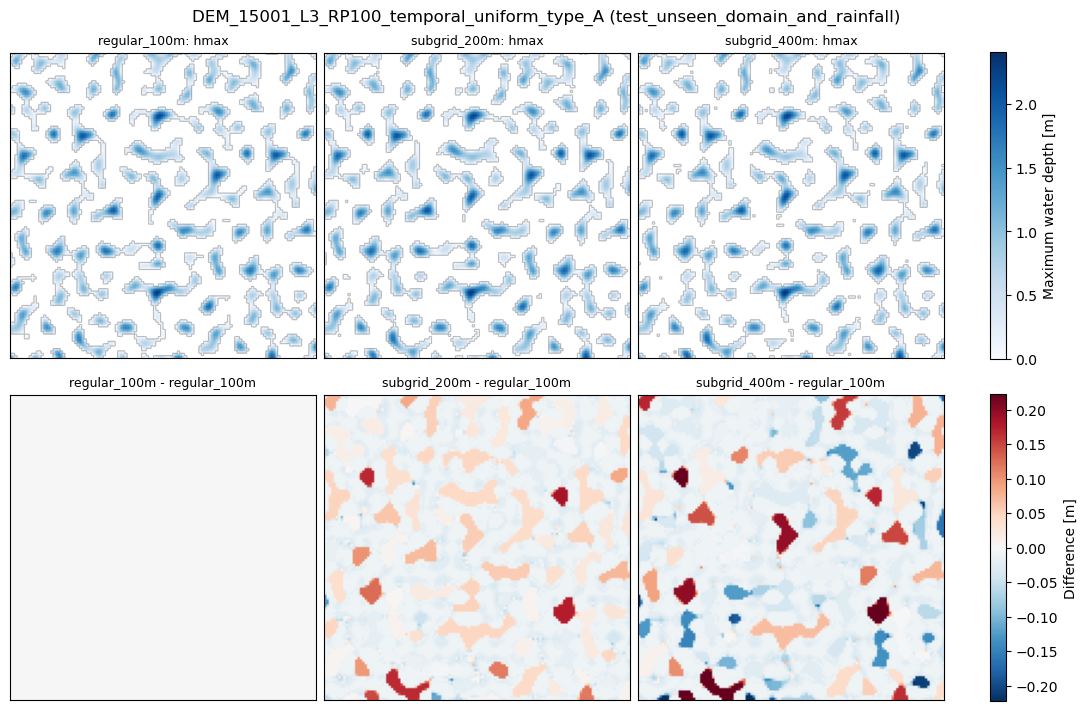

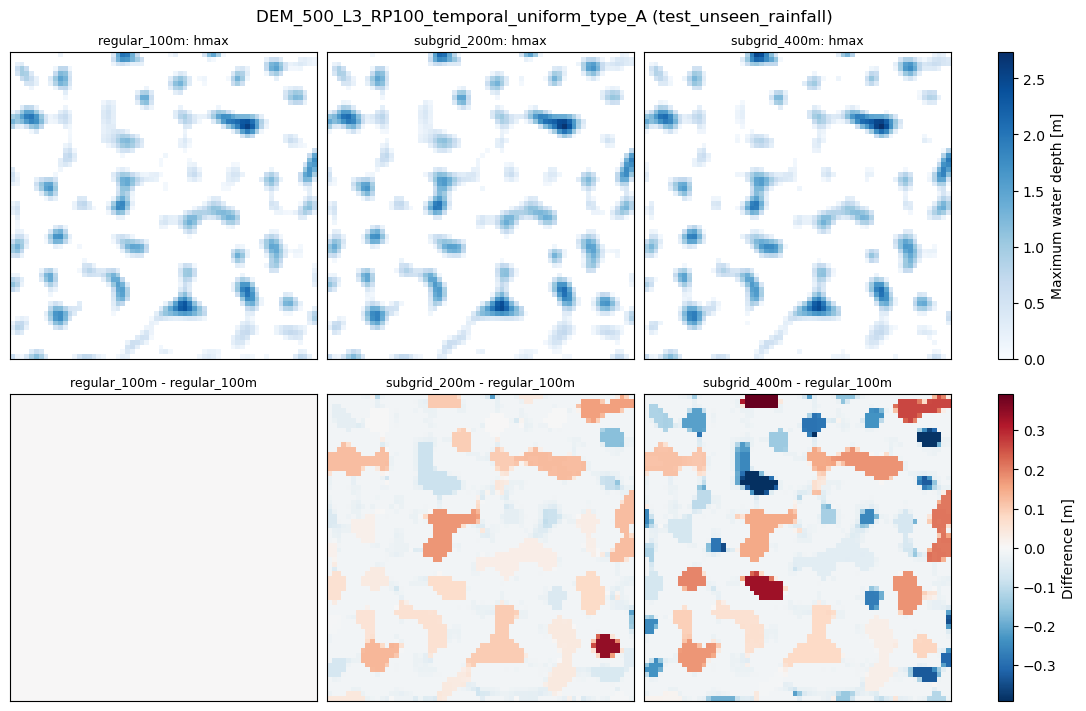

In [6]:
cases_to_plot = list(case_table.groupby("split").head(1)["case_name"])
cases_to_plot.append(subgrid.nlargest(1, "rmse_hmax_m")["case_name"].iloc[0])
cases_by_name = case_table.set_index("case_name", drop=False)

for case_name in cases_to_plot:
    plot_case(cases_by_name.loc[case_name], PROJECT_ROOT, MODEL_ROOT)

## Largest zsmax errors

In [7]:
subgrid.nlargest(10, "rmse_zsmax_m")[["case_name", "split", "variant", "rmse_zsmax_m", "bias_zsmax_m",
                                      "p95_abs_zsmax_m", "max_abs_zsmax_m"]]

,case_name,split,variant,rmse_zsmax_m,bias_zsmax_m,p95_abs_zsmax_m,max_abs_zsmax_m
47,DEM_500_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,subgrid_400m,0.234374,-0.014579,0.393850,1.779662
257,DEM_38_sloped_10m_243deg_L3_RP100_temporal_uni...,test_unseen_rainfall,subgrid_400m,0.207862,-0.038420,0.438175,1.223080
269,DEM_30_sloped_10m_10deg_L3_RP100_temporal_unif...,test_unseen_rainfall,subgrid_400m,0.198865,-0.048295,0.426483,1.652467
263,DEM_3_sloped_10m_31deg_L3_RP100_temporal_unifo...,test_unseen_rainfall,subgrid_400m,0.198277,-0.034034,0.387362,1.112247
53,DEM_23_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,subgrid_400m,0.173642,-0.003713,0.318327,0.715773
41,DEM_56_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,subgrid_400m,0.161083,-0.000508,0.333183,0.681439
260,DEM_47_sloped_10m_321deg_L3_RP100_temporal_uni...,test_unseen_rainfall,subgrid_400m,0.158313,-0.023522,0.302273,0.975348
32,DEM_20_L3_RP100_temporal_uniform_type_A,test_unseen_rainfall,subgrid_400m,0.154643,0.006627,0.304045,0.822516
266,DEM_512_sloped_10m_151deg_L3_RP100_temporal_un...,test_unseen_rainfall,subgrid_400m,0.143115,-0.024811,0.301530,1.207382
284,DEM_15001_sloped_5m_78deg_L3_RP050_temporal_un...,test_unseen_domain,subgrid_400m,0.141567,-0.002750,0.243081,1.113569


## zsmax maps: one case per split, plus the worst case

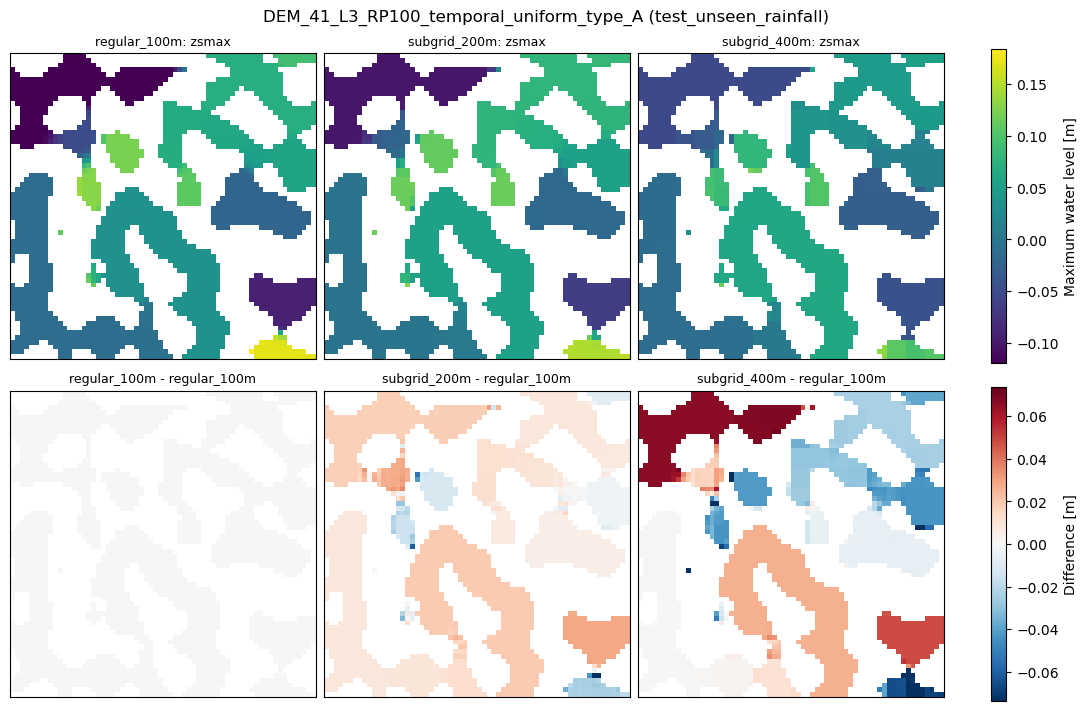

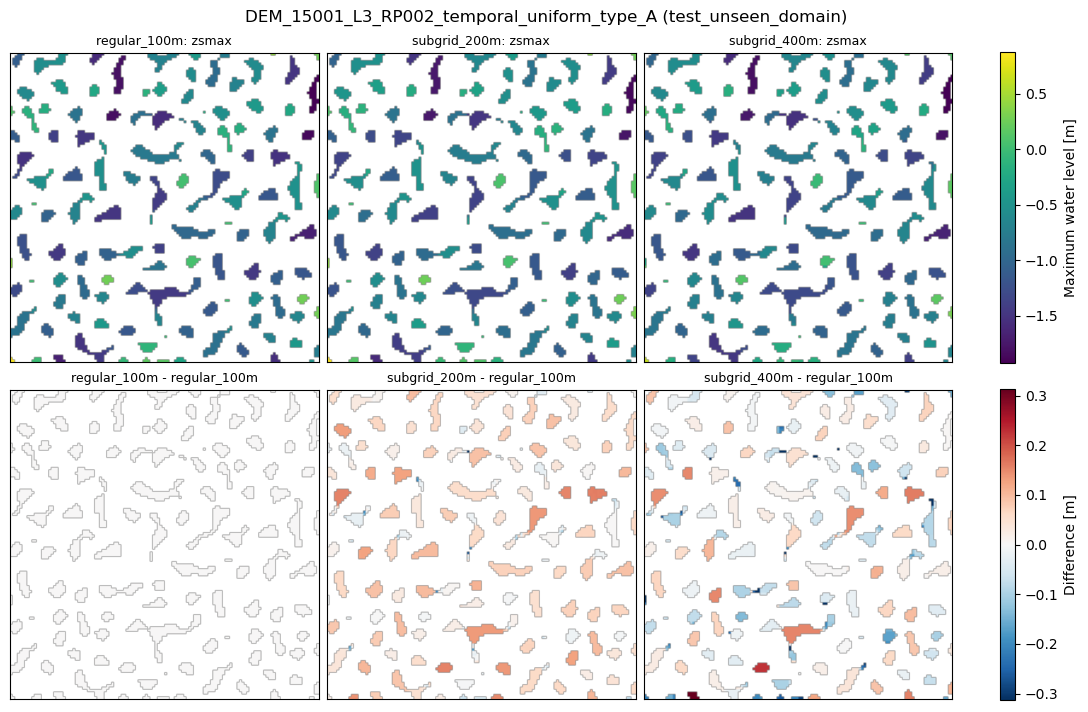

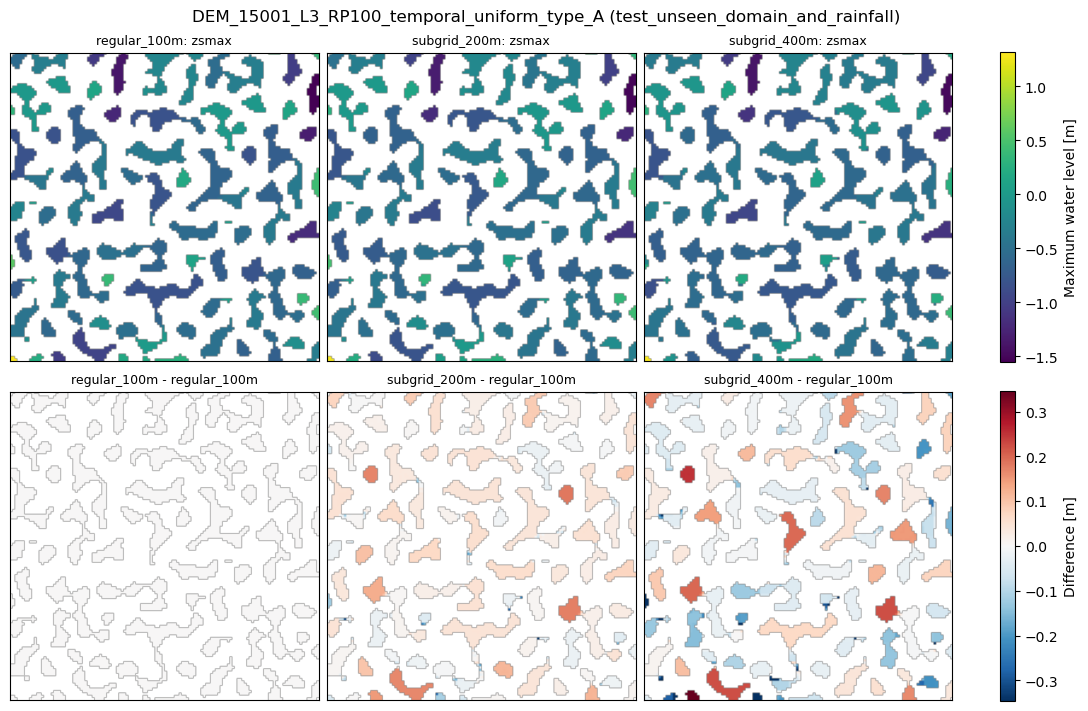

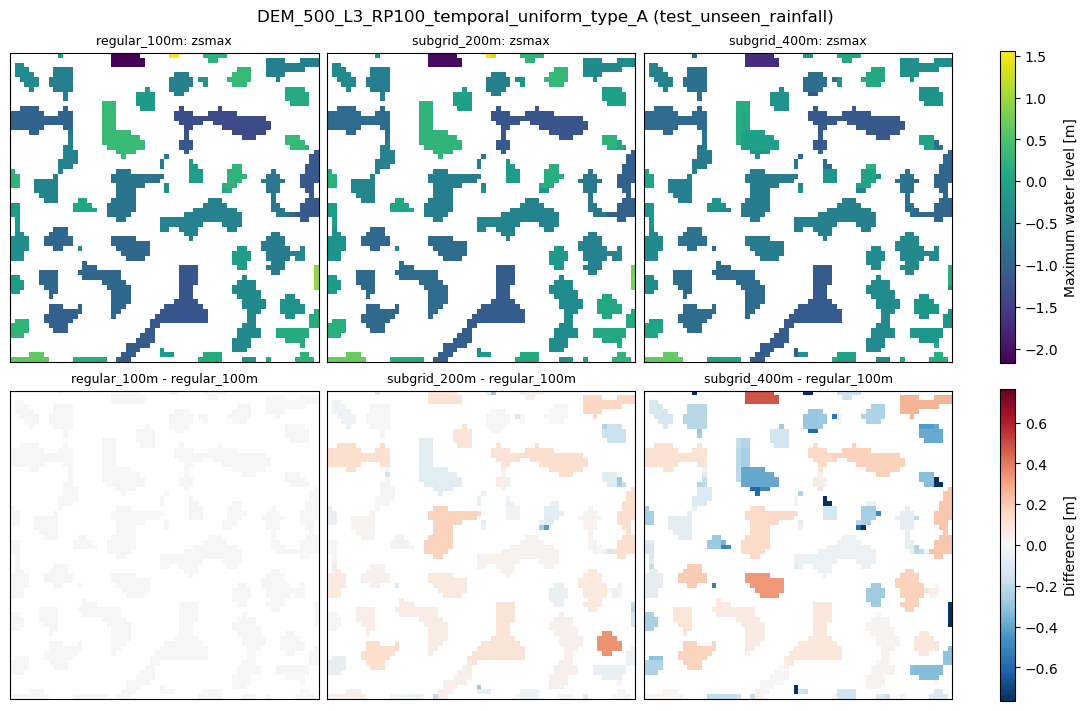

In [8]:
zsmax_cases = list(case_table.groupby("split").head(1)["case_name"])
zsmax_cases.append(subgrid.nlargest(1, "rmse_zsmax_m")["case_name"].iloc[0])

for case_name in zsmax_cases:
    plot_case(cases_by_name.loc[case_name], PROJECT_ROOT, MODEL_ROOT, quantity="zsmax")

## Summary figure

Per-case distribution (dots) and median (bar) per split; saved to `outputs/rebuild/summary_figure.png`.

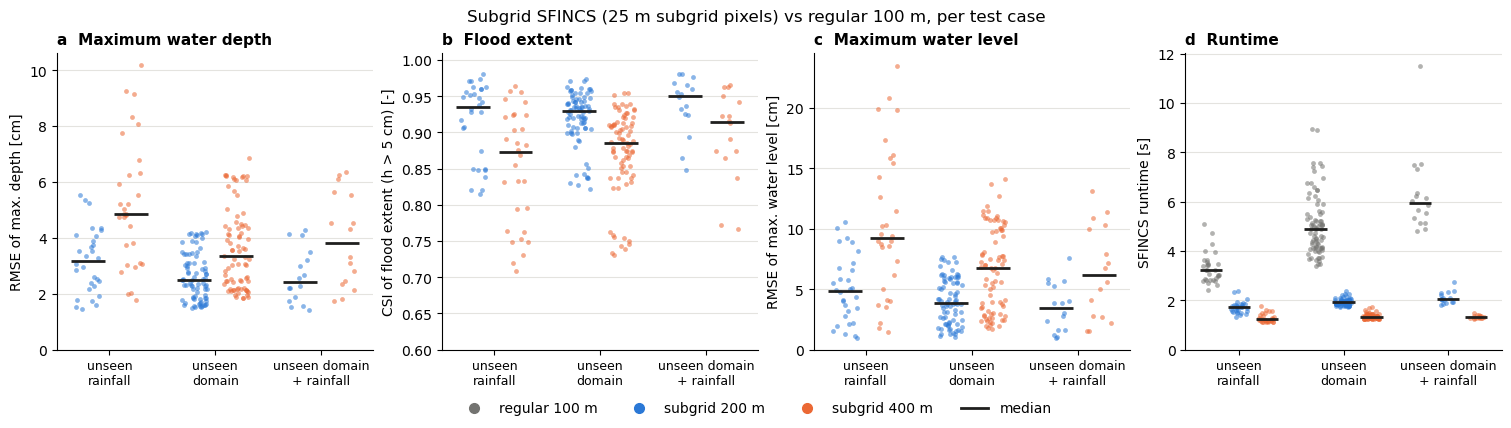

In [9]:
plot_summary(comparison, out_png=OUTPUT_FOLDER / "summary_figure.png");